# Banking Customer & Loan Analytics — LendingClub loans 2007–2011

**Author:** Jatin Gohel &nbsp;|&nbsp; **Tools:** Python (pandas, NumPy, Matplotlib, Seaborn), SQL (PostgreSQL), Excel, Power BI

## 1. Project introduction

LendingClub was the largest US peer-to-peer lending platform: borrowers applied online for unsecured personal loans
(US$1,000–35,000, 36 or 60 months), LendingClub graded each borrower A–G and set the interest rate, and investors funded
the loans. Its public loan file for 2007–2011 contains every loan issued in that period **with the final repayment outcome
(fully paid or charged off)**, which makes it ideal for portfolio and credit-risk analysis.

This notebook follows the full workflow: **raw data → understanding → data-quality checks → cleaning → feature engineering
→ EDA → KPIs → trends → segments → findings → recommendations**, and exports the cleaned table used by SQL, Excel and Power BI.

> Every number is calculated from the raw file in `data/raw/`. Re-running the notebook reproduces all tables and charts.

## 2. Business problem

The credit-risk and lending teams want to understand **the loan portfolio, who the borrowers are, which loans default and
whether interest rates compensate for the risk**, so they can tighten credit policy where losses are high and grow where
risk-adjusted returns are good.

| Area | Question |
|---|---|
| Portfolio | How many loans, how much money, what terms, grades and purposes? How did volume grow? |
| Customers | What do borrowers look like (income, employment length, home ownership, debt-to-income)? |
| Risk | What is the default (charge-off) rate and how does it differ by grade, term, purpose, income, DTI and state? |
| Pricing | Do higher interest rates compensate for higher defaults? What did each grade actually return? |
| Policy | How did loans that did *not* meet the current credit policy perform? |
| Funding | How much of the requested amount was funded? |

**What this dataset cannot answer (so it is not invented):**
* **Approval / rejection rate** — the file only contains *approved and issued* loans. LendingClub publishes rejected
  applications in a separate file (not used here), so approval rate is out of scope.
* **Branches** — LendingClub is online-only; the borrower's **state** and **US Census region** are used for regional analysis.
* **Age, gender, credit score** — not in this file (FICO ranges are not included in this version).

## 3. Dataset & source

| Item | Detail |
|---|---|
| Dataset | **LendingClub loan data, loans issued 2007–2011** (file `LoanStats3a.csv`) |
| Original publisher | LendingClub Corporation (public loan statistics). The same data is republished on Kaggle in several LendingClub datasets (e.g. *Lending Club Loan Data*). |
| Version used | Extract dated December 2015 (latest payment / credit-pull dates are Dec 2015; zip created 1 Jan 2016) |
| How obtained | Kaggle could not be reached from the build environment, so the original LendingClub zip was downloaded from a public GitHub mirror and **cross-checked against two other independent copies** (Jul 2015 and Nov 2014 extracts): the same loan ids appear in all three and borrower/loan attributes agree. Details and checksums: `data/raw/SOURCE.md`. |
| Retrieved | 22 Oct 2026 |
| Size | 42,535 loans × 74 columns (plus 1 title line and 3 non-loan text rows) |

## 4. Import libraries & chart style

In [1]:
from pathlib import Path
import io
import json
import zipfile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
CLEAN = ROOT / "data" / "cleaned"
REPORTS = ROOT / "reports"
FIG = REPORTS / "figures"
for folder in (CLEAN, FIG):
    folder.mkdir(parents=True, exist_ok=True)
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2


In [2]:
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, LIGHT_GRAY = PALETTE[0], PALETTE[1], "#c9c7bf"
GOOD, CRITICAL = "#0ca30c", "#d03b3b"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "axes.prop_cycle": plt.cycler(color=PALETTE), "lines.linewidth": 2,
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Segoe UI", "Arial", "DejaVu Sans"],
    "font.size": 10, "legend.frameon": False, "figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
})
sns.set_palette(PALETTE)


def usd(x, pos=None):
    """Compact US dollar label: $1.2M, $350K, $90."""
    def trim(v, d):
        return f"{v:.{d}f}".rstrip("0").rstrip(".")
    if abs(x) >= 1e6:
        return f"${trim(x / 1e6, 2)}M"
    if abs(x) >= 1e3:
        return f"${trim(x / 1e3, 1)}K"
    return f"${x:,.0f}"


def pct_axis(ax, axis="y", decimals=0):
    fmt = mticker.PercentFormatter(1.0, decimals=decimals)
    (ax.yaxis if axis == "y" else ax.xaxis).set_major_formatter(fmt)


def save(fig, name):
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 5. Load data

The file starts with a one-line title (`Notes offered by Prospectus…`), so the header is on line 2. It also contains a
text row that separates loans that do not meet the credit policy, and two summary rows at the end — these are not loans.

In [3]:
with zipfile.ZipFile(RAW / "LoanStats3a.csv.zip") as z:
    raw_bytes = z.read("LoanStats3a.csv")
first_line = raw_bytes.decode("utf-8", errors="replace").splitlines()[0]
print("First line of the file:", first_line)

raw = pd.read_csv(io.BytesIO(raw_bytes), skiprows=1, low_memory=False)
non_loan_rows = raw[pd.to_numeric(raw["id"], errors="coerce").isna()]
print("Non-loan text rows:", non_loan_rows["id"].tolist())
raw.head(3)

First line of the file: Notes offered by Prospectus (https://www.lendingclub.com/info/prospectus.action)


Non-loan text rows: ['Loans that do not meet the credit policy', 'Total amount funded in policy code 1: 471701350', 'Total amount funded in policy code 2: 0']


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,...,collection_recovery_fee,last_pymnt_d,last_pymnt_amnt,next_pymnt_d,last_credit_pull_d,collections_12_mths_ex_med,mths_since_last_major_derog,policy_code,application_type,annual_inc_joint,dti_joint,verification_status_joint,acc_now_delinq,tot_coll_amt,tot_cur_bal,open_acc_6m,open_il_6m,open_il_12m,open_il_24m,mths_since_rcnt_il,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_credit_rv,inq_fi,total_fi_tl,inq_last_12m
0,1077501,"1,296,599.00","5,000.00","5,000.00","4,975.00",36 months,10.65%,162.87,B,B2,NaN,10+ years,RENT,"24,000.00",Verified,Dec-2011,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I need to upgra...,credit_card,Computer,860xx,AZ,27.65,0.00,Jan-1985,1.00,NaN,NaN,...,0.00,Jan-2015,171.62,NaN,Dec-2015,0.00,NaN,1.00,INDIVIDUAL,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1077430,"1,314,167.00","2,500.00","2,500.00","2,500.00",60 months,15.27%,59.83,C,C4,Ryder,< 1 year,RENT,"30,000.00",Source Verified,Dec-2011,Charged Off,n,https://www.lendingclub.com/browse/loanDetail....,Borrower added on 12/22/11 > I plan to use t...,car,bike,309xx,GA,1.00,0.00,Apr-1999,5.00,NaN,NaN,...,1.11,Apr-2013,119.66,NaN,Sep-2013,0.00,NaN,1.00,INDIVIDUAL,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1077175,"1,313,524.00","2,400.00","2,400.00","2,400.00",36 months,15.96%,84.33,C,C5,NaN,10+ years,RENT,"12,252.00",Not Verified,Dec-2011,Fully Paid,n,https://www.lendingclub.com/browse/loanDetail....,NaN,small_business,real estate business,606xx,IL,8.72,0.00,Nov-2001,2.00,NaN,NaN,...,0.00,Jun-2014,649.91,NaN,Dec-2015,0.00,NaN,1.00,INDIVIDUAL,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 6. Dataset shape

In [4]:
print(f"Rows read: {raw.shape[0]:,} | columns: {raw.shape[1]}")
print(f"Loan rows: {raw.shape[0] - len(non_loan_rows):,}")

Rows read: 42,538 | columns: 74
Loan rows: 42,535


## 7. Data types

In [5]:
raw.dtypes.value_counts().rename("columns").to_frame()

,columns
float64,49
str,25


In [6]:
# Columns that should be numbers or dates but arrive as text
raw[["int_rate", "revol_util", "term", "emp_length", "issue_d", "earliest_cr_line", "last_pymnt_d"]].head(3)

,int_rate,revol_util,term,emp_length,issue_d,earliest_cr_line,last_pymnt_d
0,10.65%,83.7%,36 months,10+ years,Dec-2011,Jan-1985,Jan-2015
1,15.27%,9.4%,60 months,< 1 year,Dec-2011,Apr-1999,Apr-2013
2,15.96%,98.5%,36 months,10+ years,Dec-2011,Nov-2001,Jun-2014


## 8. Missing-value analysis

In [7]:
loans_raw = raw[pd.to_numeric(raw["id"], errors="coerce").notna()].copy()
missing = loans_raw.isna().mean().mul(100).round(2).sort_values(ascending=False)
empty_columns = missing[missing == 100].index.tolist()
print(f"{len(empty_columns)} columns are 100% empty (fields LendingClub added after 2011):")
print(empty_columns)
missing[(missing > 0) & (missing < 100)].rename("% missing").to_frame()

21 columns are 100% empty (fields LendingClub added after 2011):
['open_rv_24m', 'open_rv_12m', 'il_util', 'total_bal_il', 'mths_since_rcnt_il', 'open_il_24m', 'open_il_12m', 'open_il_6m', 'open_acc_6m', 'tot_cur_bal', 'tot_coll_amt', 'annual_inc_joint', 'verification_status_joint', 'mths_since_last_major_derog', 'dti_joint', 'total_fi_tl', 'inq_fi', 'total_credit_rv', 'all_util', 'inq_last_12m', 'max_bal_bc']


,% missing
mths_since_last_record,91.42
next_pymnt_d,88.40
mths_since_last_delinq,63.30
desc,31.26
emp_title,6.17
emp_length,2.61
collections_12_mths_ex_med,0.34
revol_util,0.21
last_pymnt_d,0.20
acc_now_delinq,0.07


* **21** columns are completely empty — they describe products and credit data that LendingClub only collected
  for later loans (joint applications, newer credit-bureau fields). They are dropped.
* `mths_since_last_record` / `mths_since_last_delinq` are mostly empty because most borrowers have **no** public record or
  delinquency — a blank means "never", not "unknown". They are not used as numbers.
* `next_pymnt_d` is empty for finished loans (expected). `desc` (free-text description) is optional.
* Small gaps: `emp_length` (employment length), `revol_util`, `annual_inc` and a few credit-history fields.

## 9. Duplicate analysis

In [8]:
print("Fully duplicated rows:", loans_raw.duplicated().sum())
print("Duplicate loan ids:", loans_raw["id"].duplicated().sum())
print("Duplicate member ids:", loans_raw["member_id"].duplicated().sum())

Fully duplicated rows: 0
Duplicate loan ids: 0
Duplicate member ids: 0


No duplicates: every loan and every borrower (`member_id`) appears once, so each row is one borrower and one loan.

## 10. Data-quality checks

In [9]:
to_number = lambda s: pd.to_numeric(s.astype(str).str.strip().str.rstrip("%"), errors="coerce")
chk = loans_raw.assign(int_rate_n=to_number(loans_raw["int_rate"]),
                       term_n=loans_raw["term"].str.extract(r"(\d+)")[0].astype(int))

dq = {}
# 1. Reconcile with LendingClub's own control total printed at the end of the file
footer_total = float(non_loan_rows["id"].str.extract(r"policy code 1: (\d+)")[0].dropna().iloc[0])
dq["sum of loan_amnt equals file control total"] = bool(chk["loan_amnt"].sum() == footer_total)
# 2. Installment must follow the standard amortisation formula
r = chk["int_rate_n"] / 1200
expected_installment = chk["funded_amnt"] * r / (1 - (1 + r) ** -chk["term_n"])
dq["installment matches amortisation formula (±$1)"] = f"{((expected_installment - chk['installment']).abs() <= 1).mean():.2%}"
# 3. Funded amount can never exceed requested amount
dq["funded_amnt > loan_amnt"] = int((chk["funded_amnt"] > chk["loan_amnt"]).sum())
dq["funded_amnt < loan_amnt (partly funded)"] = int((chk["funded_amnt"] < chk["loan_amnt"]).sum())
# 4. Ranges
dq["interest rate range (%)"] = f"{chk['int_rate_n'].min()} – {chk['int_rate_n'].max()}"
dq["DTI range"] = f"{chk['dti'].min()} – {chk['dti'].max()}"
dq["annual income range ($)"] = f"{chk['annual_inc'].min():,.0f} – {chk['annual_inc'].max():,.0f}"
# 5. Payment components add up (total_pymnt = principal + interest + late fees + recoveries)
parts = chk["total_rec_prncp"] + chk["total_rec_int"] + chk["total_rec_late_fee"] + chk["recoveries"]
dq["total_pymnt equals its components (±$0.02)"] = f"{((chk['total_pymnt'] - parts).abs() <= 0.02).mean():.2%}"
# 6. Recoveries only on charged-off loans
dq["loans with recoveries that are not charged off"] = int(((chk["recoveries"] > 0) & ~chk["loan_status"].str.contains("Charged Off")).sum())
# 7. Single-value columns (no information)
single_value = [c for c in loans_raw.columns if loans_raw[c].nunique(dropna=True) == 1]
dq["columns with a single value"] = ", ".join(single_value)
pd.Series(dq, name="result").to_frame()

,result
sum of loan_amnt equals file control total,True
installment matches amortisation formula (±$1),99.97%
funded_amnt > loan_amnt,0
funded_amnt < loan_amnt (partly funded),1997
interest rate range (%),5.42 – 24.59
DTI range,0.0 – 29.99
annual income range ($),"1,896 – 6,000,000"
total_pymnt equals its components (±$0.02),100.00%
loans with recoveries that are not charged off,0
columns with a single value,"initial_list_status, collections_12_mths_ex_me..."


In [10]:
print("Loan status values:")
loans_raw["loan_status"].value_counts()

Loan status values:


loan_status
Fully Paid                                             32036
Charged Off                                             5565
Current                                                 2080
Does not meet the credit policy. Status:Fully Paid      1984
Does not meet the credit policy. Status:Charged Off      761
Late (31-120 days)                                        66
In Grace Period                                           31
Late (16-30 days)                                          7
Does not meet the credit policy. Status:Current            4
Default                                                    1
Name: count, dtype: int64

**Data-quality conclusions**

1. The file passes LendingClub's own control total: the sum of loan amounts equals the total printed in the file footer.
2. Installments follow the amortisation formula for 99.97% of loans and payment components add up — the money fields are reliable.
3. No loan is funded above the requested amount; 1,997 loans were only partly funded.
4. `loan_status` mixes two things: the outcome (Fully Paid / Charged Off / Current…) and whether the loan meets the
   *current* credit policy ("Does not meet the credit policy. Status: …"). These are split into two columns.
5. Rates and utilisation are stored as text ("10.65%"), term as " 36 months", employment length as "10+ years" — all converted.
6. `policy_code`, `application_type`, `initial_list_status` have a single value and carry no information.

## 11. Data cleaning (every step logged)

In [11]:
cleaning_log = []


def log(step, rows_affected, action):
    cleaning_log.append({"step": step, "rows_affected": int(rows_affected), "action": action})


log("Skip the title line above the header", 1, "parsing")
log("Remove non-loan text rows (section separator + 2 footer totals)", len(non_loan_rows), "remove invalid rows")
df = loans_raw.copy()
df["id"] = df["id"].astype(int)
df["member_id"] = df["member_id"].astype(int)

drop_cols = empty_columns + single_value + ["url", "desc", "pymnt_plan", "out_prncp_inv", "total_pymnt_inv"]
drop_cols = list(dict.fromkeys(drop_cols))
df = df.drop(columns=drop_cols)
log(f"Drop {len(drop_cols)} columns (empty, single-value, URL, free-text description, duplicates of other fields)", 0, "remove columns")

# Text -> numbers
df["int_rate"] = to_number(df["int_rate"])
df["revol_util"] = to_number(df["revol_util"])
df["term_months"] = df["term"].str.extract(r"(\d+)")[0].astype(int)
df = df.drop(columns="term")
log("Convert int_rate, revol_util ('10.65%') and term (' 36 months') to numbers", len(df), "type conversion")

# Employment length: '10+ years' -> 10, '< 1 year' -> 0, missing stays missing
emp_map = {"< 1 year": 0, "1 year": 1, "10+ years": 10}
emp_map.update({f"{i} years": i for i in range(2, 10)})
log("Employment length missing (kept as 'Unknown')", df["emp_length"].isna().sum(), "missing values")
df["emp_length_years"] = df["emp_length"].map(emp_map)
df["emp_length"] = df["emp_length"].fillna("Unknown")
log("Convert emp_length text to years (0–10)", df["emp_length_years"].notna().sum(), "type conversion")

# Dates ('Dec-2011' -> 2011-12-01)
for col in ["issue_d", "earliest_cr_line", "last_pymnt_d", "next_pymnt_d", "last_credit_pull_d"]:
    df[col] = pd.to_datetime(df[col], format="%b-%Y", errors="coerce")
log("Convert 5 month-year text columns to dates", len(df), "date conversion")

# Split loan_status into outcome + credit-policy flag
df["meets_credit_policy"] = ~df["loan_status"].str.startswith("Does not meet")
df["loan_status"] = df["loan_status"].str.replace("Does not meet the credit policy. Status:", "", regex=False).str.strip()
log("Split 'Does not meet the credit policy' into its own flag", (~df["meets_credit_policy"]).sum(), "standardisation")

# Home ownership: NONE (8 loans) merged into OTHER
none_rows = (df["home_ownership"] == "NONE").sum()
df["home_ownership"] = df["home_ownership"].replace({"NONE": "OTHER"})
log("Merge home_ownership 'NONE' into 'OTHER'", none_rows, "standardisation")

# Text cleanup
df["emp_title"] = df["emp_title"].str.strip().str.lower()
df["title"] = df["title"].str.strip()
df["purpose"] = df["purpose"].str.replace("_", " ").str.capitalize()
log("Lower-case employer titles, tidy purpose labels ('debt_consolidation' -> 'Debt consolidation')", len(df), "standardisation")

# Missing values that are kept
log("annual_inc missing (kept; excluded from income analysis)", df["annual_inc"].isna().sum(), "missing values")
log("revol_util missing (kept; excluded from utilisation analysis)", df["revol_util"].isna().sum(), "missing values")
log("Credit-history fields missing for the same loans (kept)", df["earliest_cr_line"].isna().sum(), "missing values")
print(df.shape)
pd.DataFrame(cleaning_log)

(42535, 46)


,step,rows_affected,action
0,Skip the title line above the header,1,parsing
1,Remove non-loan text rows (section separator +...,3,remove invalid rows
2,"Drop 30 columns (empty, single-value, URL, fre...",0,remove columns
3,"Convert int_rate, revol_util ('10.65%') and te...",42535,type conversion
4,Employment length missing (kept as 'Unknown'),1112,missing values
5,Convert emp_length text to years (0–10),41423,type conversion
6,Convert 5 month-year text columns to dates,42535,date conversion
7,Split 'Does not meet the credit policy' into i...,2749,standardisation
8,Merge home_ownership 'NONE' into 'OTHER',8,standardisation
9,"Lower-case employer titles, tidy purpose label...",42535,standardisation


## 12. Feature engineering

**Outcome definitions (used identically in Python, SQL, Excel and Power BI)**

| Field | Rule |
|---|---|
| `outcome` | **Fully Paid**; **Charged Off** (incl. the 1 loan in "Default" status — 121+ days late); **Active** = Current, In Grace Period, Late (16–30 / 31–120 days) |
| `is_resolved` | outcome is Fully Paid or Charged Off (the loan has finished) |
| `is_bad` | outcome = Charged Off |
| **Default rate** | bad loans ÷ resolved loans (active loans are excluded — their outcome is not known yet) |
| **Net return** | (total payments received − funded amount) ÷ funded amount, resolved loans only (total over the loan's life, not annualised) |
| **Net principal loss** | funded amount − principal repaid − recoveries (charged-off loans) |

In [12]:
df["outcome"] = np.select(
    [df["loan_status"].eq("Fully Paid"), df["loan_status"].isin(["Charged Off", "Default"])],
    ["Fully Paid", "Charged Off"], default="Active")
df["is_resolved"] = df["outcome"].isin(["Fully Paid", "Charged Off"])
df["is_bad"] = df["outcome"].eq("Charged Off")

# Time
df["issue_year"] = df["issue_d"].dt.year
df["issue_month"] = df["issue_d"].dt.to_period("M").astype(str)
df["issue_quarter"] = df["issue_d"].dt.to_period("Q").astype(str)
df["credit_history_years"] = ((df["issue_d"] - df["earliest_cr_line"]).dt.days / 365.25).round(1)

# Money
df["funding_gap"] = df["loan_amnt"] - df["funded_amnt"]
df["net_return"] = np.where(df["is_resolved"], (df["total_pymnt"] - df["funded_amnt"]) / df["funded_amnt"], np.nan)
df["net_principal_loss"] = np.where(df["is_bad"], df["funded_amnt"] - df["total_rec_prncp"] - df["recoveries"], 0.0)
df["installment_to_income"] = (df["installment"] * 12 / df["annual_inc"]).round(4)

# Bands for segment analysis
df["income_band"] = pd.cut(df["annual_inc"], [0, 30_000, 50_000, 75_000, 100_000, 150_000, np.inf],
                           labels=["<30K", "30–50K", "50–75K", "75–100K", "100–150K", "150K+"], right=False)
df["dti_band"] = pd.cut(df["dti"], [0, 5, 10, 15, 20, 25, 30.01], right=False,
                        labels=["0–5", "5–10", "10–15", "15–20", "20–25", "25–30"])
df["loan_amount_band"] = pd.cut(df["loan_amnt"], [0, 5_000, 10_000, 15_000, 20_000, 25_000, 35_001], right=False,
                                labels=["<5K", "5–10K", "10–15K", "15–20K", "20–25K", "25–35K"])
df["revol_util_band"] = pd.cut(df["revol_util"], [0, 25, 50, 75, 100, np.inf], right=False,
                               labels=["0–25%", "25–50%", "50–75%", "75–100%", "100%+"])

# Region (US Census Bureau regions — reference data, not from LendingClub)
census = {
    "Northeast": ["CT", "ME", "MA", "NH", "RI", "VT", "NJ", "NY", "PA"],
    "Midwest": ["IL", "IN", "MI", "OH", "WI", "IA", "KS", "MN", "MO", "NE", "ND", "SD"],
    "South": ["DE", "DC", "FL", "GA", "MD", "NC", "SC", "VA", "WV", "AL", "KY", "MS", "TN", "AR", "LA", "OK", "TX"],
    "West": ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY", "AK", "CA", "HI", "OR", "WA"],
}
state_names = {
    "AL": "Alabama", "AK": "Alaska", "AZ": "Arizona", "AR": "Arkansas", "CA": "California", "CO": "Colorado",
    "CT": "Connecticut", "DE": "Delaware", "DC": "District of Columbia", "FL": "Florida", "GA": "Georgia",
    "HI": "Hawaii", "ID": "Idaho", "IL": "Illinois", "IN": "Indiana", "IA": "Iowa", "KS": "Kansas",
    "KY": "Kentucky", "LA": "Louisiana", "ME": "Maine", "MD": "Maryland", "MA": "Massachusetts", "MI": "Michigan",
    "MN": "Minnesota", "MS": "Mississippi", "MO": "Missouri", "MT": "Montana", "NE": "Nebraska", "NV": "Nevada",
    "NH": "New Hampshire", "NJ": "New Jersey", "NM": "New Mexico", "NY": "New York", "NC": "North Carolina",
    "ND": "North Dakota", "OH": "Ohio", "OK": "Oklahoma", "OR": "Oregon", "PA": "Pennsylvania", "RI": "Rhode Island",
    "SC": "South Carolina", "SD": "South Dakota", "TN": "Tennessee", "TX": "Texas", "UT": "Utah", "VT": "Vermont",
    "VA": "Virginia", "WA": "Washington", "WV": "West Virginia", "WI": "Wisconsin", "WY": "Wyoming",
}
dim_state = pd.DataFrame([(code, state_names[code], region) for region, codes in census.items() for code in codes],
                         columns=["state_code", "state_name", "region"]).sort_values("state_code")
assert set(df["addr_state"]) <= set(dim_state["state_code"])
df["region"] = df["addr_state"].map(dim_state.set_index("state_code")["region"])
dim_state.to_csv(CLEAN / "dim_state.csv", index=False)

# High-value customer flag: top 10% income
income_p90 = df["annual_inc"].quantile(0.90)
df["is_high_income"] = df["annual_inc"] >= income_p90
print(f"Top-10% income threshold: ${income_p90:,.0f}")
df[["id", "grade", "int_rate", "loan_status", "outcome", "is_bad", "net_return", "income_band", "region"]].head()

Top-10% income threshold: $116,736


,id,grade,int_rate,loan_status,outcome,is_bad,net_return,income_band,region
0,1077501,B,10.65,Fully Paid,Fully Paid,False,0.17,<30K,West
1,1077430,C,15.27,Charged Off,Charged Off,True,-0.60,30–50K,South
2,1077175,C,15.96,Fully Paid,Fully Paid,False,0.25,<30K,Midwest
3,1076863,C,13.49,Fully Paid,Fully Paid,False,0.22,30–50K,West
4,1075358,B,12.69,Current,Active,False,NaN,75–100K,West


In [13]:
keep = ["id", "member_id", "issue_d", "issue_year", "issue_quarter", "issue_month", "loan_amnt", "funded_amnt",
        "funded_amnt_inv", "funding_gap", "term_months", "int_rate", "installment", "grade", "sub_grade",
        "purpose", "title", "emp_title", "emp_length", "emp_length_years", "home_ownership", "annual_inc",
        "income_band", "is_high_income", "verification_status", "addr_state", "region", "zip_code", "dti", "dti_band",
        "delinq_2yrs", "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "revol_util_band",
        "total_acc", "earliest_cr_line", "credit_history_years", "loan_amount_band", "installment_to_income",
        "loan_status", "meets_credit_policy", "outcome", "is_resolved", "is_bad", "total_pymnt", "total_rec_prncp",
        "total_rec_int", "total_rec_late_fee", "recoveries", "collection_recovery_fee", "out_prncp", "last_pymnt_d",
        "last_pymnt_amnt", "net_return", "net_principal_loss"]
loans = df[keep].copy()
for col in ["delinq_2yrs", "inq_last_6mths", "open_acc", "pub_rec", "total_acc", "emp_length_years"]:
    loans[col] = loans[col].astype("Int64")          # whole numbers (nullable) — cleaner CSV for SQL/Excel
for col in ["net_return", "installment_to_income"]:
    loans[col] = loans[col].round(6)
for col in ["issue_d", "earliest_cr_line", "last_pymnt_d"]:
    loans[col] = loans[col].dt.date
loans.to_csv(CLEAN / "loans_clean.csv", index=False)
pd.DataFrame(cleaning_log).to_csv(REPORTS / "cleaning_log.csv", index=False)
pd.Series(dq, name="result").to_csv(REPORTS / "data_quality_checks.csv")
print(f"loans_clean.csv: {len(loans):,} rows x {loans.shape[1]} columns")

loans_clean.csv: 42,535 rows x 58 columns


## 13. Descriptive statistics

In [14]:
df[["loan_amnt", "funded_amnt", "int_rate", "installment", "annual_inc", "dti", "revol_util", "credit_history_years",
    "open_acc", "inq_last_6mths"]].describe().T

,count,mean,std,min,25%,50%,75%,max
loan_amnt,"42,535.00","11,089.72","7,410.94",500.00,"5,200.00","9,700.00","15,000.00","35,000.00"
funded_amnt,"42,535.00","10,821.59","7,146.91",500.00,"5,000.00","9,600.00","15,000.00","35,000.00"
int_rate,"42,535.00",12.17,3.71,5.42,9.63,11.99,14.72,24.59
installment,"42,535.00",322.62,208.93,15.67,165.52,277.69,428.18,"1,305.19"
annual_inc,"42,531.00","69,136.56","64,096.35","1,896.00","40,000.00","59,000.00","82,500.00","6,000,000.00"
dti,"42,535.00",13.37,6.73,0.00,8.20,13.47,18.68,29.99
revol_util,"42,445.00",49.12,28.36,0.00,25.70,49.70,72.70,119.00
credit_history_years,"42,506.00",13.67,6.89,0.50,9.00,12.50,17.00,65.40
open_acc,"42,506.00",9.34,4.50,1.00,6.00,9.00,12.00,47.00
inq_last_6mths,"42,506.00",1.08,1.53,0.00,0.00,1.00,2.00,33.00


In [15]:
q1, q3 = df["annual_inc"].quantile([0.25, 0.75])
fence = q3 + 1.5 * (q3 - q1)
print(f"Income IQR upper fence: ${fence:,.0f} — {(df['annual_inc'] > fence).sum():,} borrowers above it "
      f"(max ${df['annual_inc'].max():,.0f}). Kept: incomes are self-reported but plausible; analysis uses medians and bands.")

Income IQR upper fence: $146,250 — 2,032 borrowers above it (max $6,000,000). Kept: incomes are self-reported but plausible; analysis uses medians and bands.


## 14. Exploratory data analysis

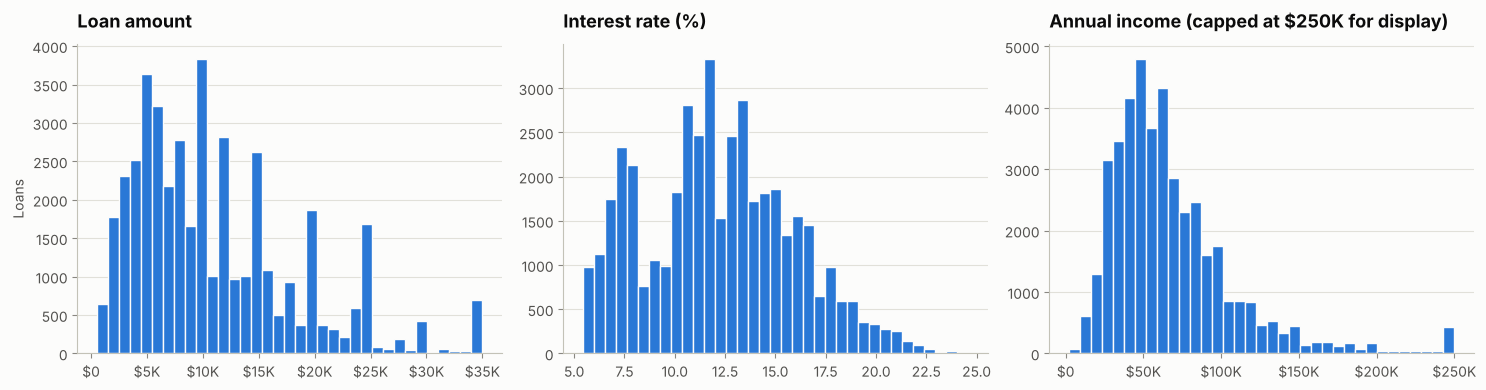

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["loan_amnt"], bins=35, color=BLUE, edgecolor=SURFACE)
axes[0].xaxis.set_major_formatter(mticker.FuncFormatter(usd))
axes[0].set_title("Loan amount")
axes[0].set_ylabel("Loans")
axes[1].hist(df["int_rate"], bins=35, color=BLUE, edgecolor=SURFACE)
axes[1].set_title("Interest rate (%)")
axes[2].hist(df["annual_inc"].clip(upper=250_000), bins=35, color=BLUE, edgecolor=SURFACE)
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(usd))
axes[2].set_title("Annual income (capped at $250K for display)")
for ax in axes:
    ax.grid(axis="y")
fig.tight_layout()
save(fig, "01_distributions")

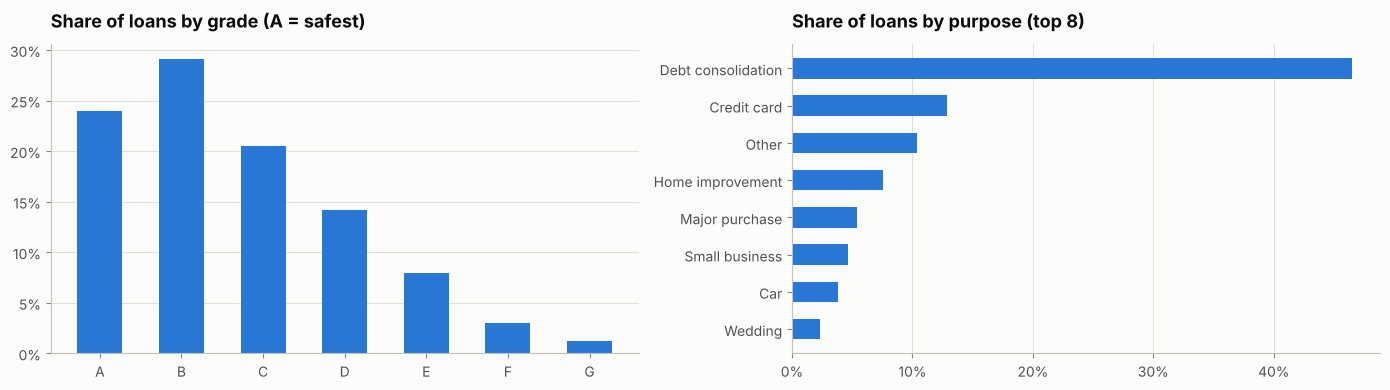

Term mix: {'36 months': '74.1%', '60 months': '25.9%'}


In [17]:
mix = pd.DataFrame({
    "Grade": df["grade"].value_counts(normalize=True).sort_index(),
})
term_mix = df["term_months"].value_counts(normalize=True)
purpose_mix = df["purpose"].value_counts(normalize=True).head(8)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(mix.index, mix["Grade"], color=BLUE, width=0.55)
pct_axis(axes[0])
axes[0].set_title("Share of loans by grade (A = safest)")
axes[0].grid(axis="y")
axes[1].barh(purpose_mix.index[::-1], purpose_mix.values[::-1], color=BLUE, height=0.55)
pct_axis(axes[1], "x")
axes[1].set_title("Share of loans by purpose (top 8)")
axes[1].grid(axis="x")
fig.tight_layout()
save(fig, "02_grade_and_purpose_mix")
print("Term mix:", {f"{k} months": f"{v:.1%}" for k, v in term_mix.items()})

## 15. KPI calculations

In [18]:
res = df[df["is_resolved"]]
bad = df[df["is_bad"]]
kpi = {
    "loans": len(df),
    "borrowers": df["member_id"].nunique(),
    "requested_amount": df["loan_amnt"].sum(),
    "funded_amount": df["funded_amnt"].sum(),
    "investor_funded_amount": df["funded_amnt_inv"].sum(),
    "funding_rate": df["funded_amnt"].sum() / df["loan_amnt"].sum(),
    "fully_funded_loans_share": (df["funded_amnt"] == df["loan_amnt"]).mean(),
    "avg_loan_amount": df["loan_amnt"].mean(),
    "median_loan_amount": df["loan_amnt"].median(),
    "avg_int_rate": df["int_rate"].mean(),
    "weighted_avg_int_rate": np.average(df["int_rate"], weights=df["funded_amnt"]),
    "share_60_month": (df["term_months"] == 60).mean(),
    "median_income": df["annual_inc"].median(),
    "avg_dti": df["dti"].mean(),
    "resolved_loans": len(res),
    "active_loans": int((~df["is_resolved"]).sum()),
    "fully_paid_loans": int((df["outcome"] == "Fully Paid").sum()),
    "charged_off_loans": len(bad),
    "default_rate": res["is_bad"].mean(),
    "principal_lost": bad["net_principal_loss"].sum(),
    "loss_rate_on_funded": bad["net_principal_loss"].sum() / res["funded_amnt"].sum(),
    "lgd_charged_off": bad["net_principal_loss"].sum() / bad["funded_amnt"].sum(),
    "recoveries": bad["recoveries"].sum(),
    "portfolio_net_return": res["total_pymnt"].sum() / res["funded_amnt"].sum() - 1,
    "interest_received": df["total_rec_int"].sum(),
    "policy_exception_loans": int((~df["meets_credit_policy"]).sum()),
    "policy_exception_share": (~df["meets_credit_policy"]).mean(),
    "states": df["addr_state"].nunique(),
}
kpi_table = pd.Series(kpi).to_frame("value")
kpi_table

,value
loans,"42,535.00"
borrowers,"42,535.00"
requested_amount,"471,701,350.00"
funded_amount,"460,296,150.00"
investor_funded_amount,"431,297,694.63"
funding_rate,0.98
fully_funded_loans_share,0.95
avg_loan_amount,"11,089.72"
median_loan_amount,"9,700.00"
avg_int_rate,12.17


**Why these KPIs:** volume and funded amount measure the portfolio's size; average loan, interest rate, term mix and
income describe the product and the customer; **default rate, principal lost and loss-given-default** measure credit risk;
**net return** shows whether interest income covered the losses; funding rate shows how much demand investors met.

## 16. Trend analysis — growth and vintage performance

In [19]:
vintage = df.groupby("issue_year").agg(loans=("id", "count"), funded=("funded_amnt", "sum"),
                                       avg_rate=("int_rate", "mean"), share_60m=("term_months", lambda s: (s == 60).mean()))
vintage["default_rate"] = res.groupby("issue_year")["is_bad"].mean()
vintage["resolved_share"] = df.groupby("issue_year")["is_resolved"].mean()
vintage["funded_growth_pct"] = vintage["funded"].pct_change() * 100
vintage

,loans,funded,avg_rate,share_60m,default_rate,resolved_share,funded_growth_pct
issue_year,,,,,,,
2007,603,"4,791,550.00",11.83,0.00,0.26,1.00,NaN
2008,2393,"19,975,025.00",12.06,0.00,0.21,1.00,316.88
2009,5281,"51,814,750.00",12.44,0.00,0.14,1.00,159.40
2010,12537,"126,351,175.00",11.99,0.27,0.14,0.99,143.85
2011,21721,"257,363,650.00",12.22,0.35,0.16,0.90,103.69


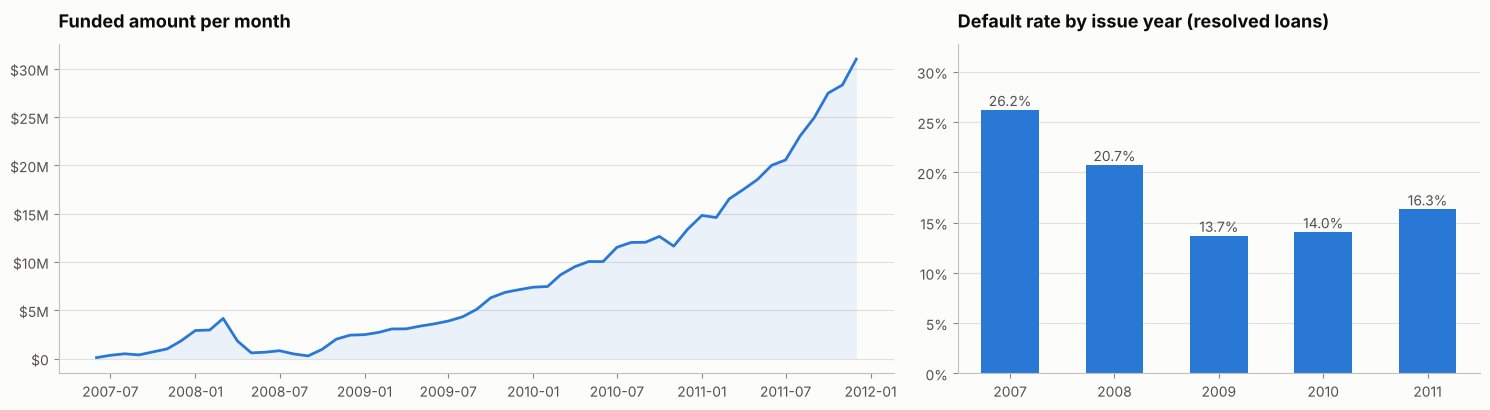

Loans issued in 2011 that were still active in Dec 2015: 9.8%


In [20]:
monthly = df.groupby(df["issue_d"].dt.to_period("M"))["funded_amnt"].sum()
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
ax = axes[0]
ax.plot(monthly.index.to_timestamp(), monthly.values, color=BLUE)
ax.fill_between(monthly.index.to_timestamp(), monthly.values, color=BLUE, alpha=0.08, linewidth=0)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(usd))
ax.set_title("Funded amount per month")
ax.grid(axis="y")
ax = axes[1]
ax.bar(vintage.index.astype(str), vintage["default_rate"], color=BLUE, width=0.55)
for x, v in zip(vintage.index.astype(str), vintage["default_rate"]):
    ax.text(x, v + 0.004, f"{v:.1%}", ha="center", color=INK_2)
pct_axis(ax)
ax.set_ylim(0, vintage["default_rate"].max() * 1.25)
ax.set_title("Default rate by issue year (resolved loans)")
ax.grid(axis="y")
fig.tight_layout()
save(fig, "03_growth_and_vintage_default")
active_2011 = 1 - vintage.loc[2011, "resolved_share"]
print(f"Loans issued in 2011 that were still active in Dec 2015: {active_2011:.1%}")

**Caution when reading vintages:** the default rate uses *finished* loans only. In the 2011 vintage a share of loans
(mostly 60-month loans) was still running when the data was extracted. Loans that are still paying are, by definition,
not defaulted yet, so the 2011 rate among finished loans is biased upwards. Compare vintages carefully, and prefer
older vintages for final conclusions.

## 17. Segment analysis

### 17.1 Grade — does pricing match risk?

In [21]:
def risk_table(by, data=df):
    resolved = data[data["is_resolved"]]
    t = data.groupby(by, observed=True).agg(loans=("id", "count"), funded=("funded_amnt", "sum"),
                                            avg_rate=("int_rate", "mean"))
    t["share_of_loans"] = t["loans"] / t["loans"].sum()
    t["resolved_loans"] = resolved.groupby(by, observed=True)["id"].count()
    t["default_rate"] = resolved.groupby(by, observed=True)["is_bad"].mean()
    t["net_return"] = (resolved.groupby(by, observed=True)["total_pymnt"].sum()
                       / resolved.groupby(by, observed=True)["funded_amnt"].sum() - 1)
    return t


grade = risk_table("grade")
grade

,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
grade,,,,,,,
A,10183,"85,295,150.00",7.34,0.24,10115,0.06,0.07
B,12389,"133,714,950.00",11.01,0.29,11756,0.13,0.09
C,8740,"93,102,750.00",13.50,0.21,8229,0.18,0.09
D,6016,"70,068,700.00",15.58,0.14,5583,0.23,0.09
E,3394,"48,061,025.00",17.38,0.08,3041,0.28,0.10
F,1301,"21,511,400.00",19.27,0.03,1145,0.36,0.06
G,512,"8,542,175.00",20.45,0.01,478,0.36,0.09


In [22]:
# Total return depends on how long money is lent, and low grades have more 60-month loans.
# Comparing grades within 36-month loans only gives a like-for-like view.
grade_36 = risk_table("grade", df[df["term_months"] == 36])
grade_36[["loans", "avg_rate", "default_rate", "net_return"]]

,loans,avg_rate,default_rate,net_return
grade,,,,
A,9745,7.34,0.06,0.07
B,9664,10.99,0.11,0.09
C,6342,13.41,0.16,0.09
D,3849,15.20,0.19,0.10
E,1301,16.39,0.23,0.10
F,413,17.72,0.32,0.00
G,220,19.03,0.36,0.03


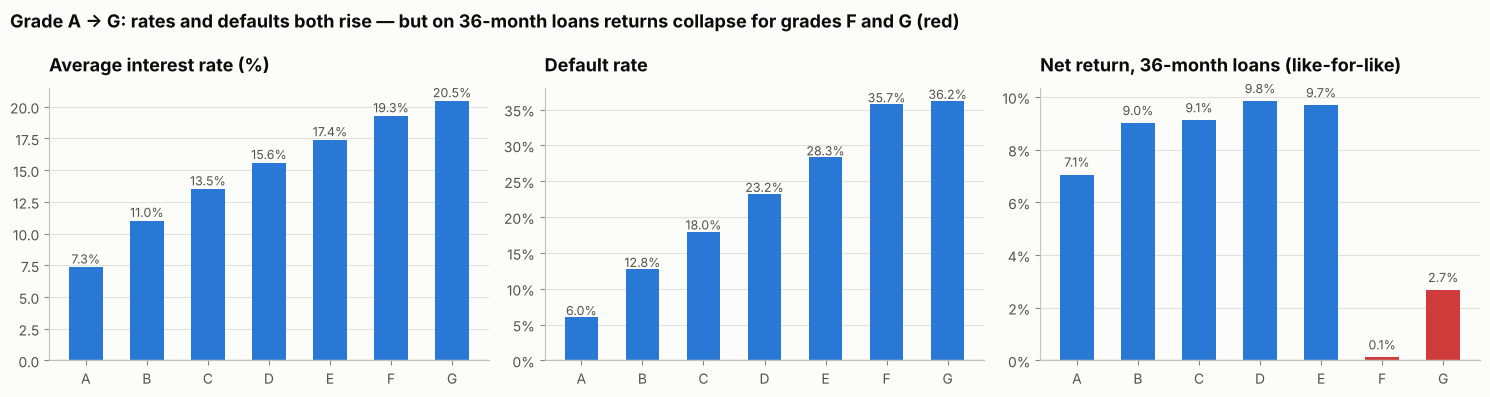

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, t, col, title, fmt in [(axes[0], grade, "avg_rate", "Average interest rate (%)", "{:.1f}%"),
                               (axes[1], grade, "default_rate", "Default rate", "{:.1%}"),
                               (axes[2], grade_36, "net_return", "Net return, 36-month loans (like-for-like)", "{:.1%}")]:
    colors = [BLUE] * len(t)
    if col == "net_return":
        colors = [CRITICAL if v < t[col].max() / 3 else BLUE for v in t[col]]
    ax.bar(t.index, t[col], color=colors, width=0.55)
    for x, v in zip(t.index, t[col]):
        ax.text(x, v + (0.003 if col != "avg_rate" else 0.3) * (1 if v >= 0 else -4), fmt.format(v), ha="center", color=INK_2, fontsize=9)
    ax.set_title(title)
    ax.grid(axis="y")
    if col != "avg_rate":
        pct_axis(ax)
    ax.axhline(0, color=AXIS, linewidth=1)
fig.suptitle("Grade A → G: rates and defaults both rise — but on 36-month loans returns collapse for grades F and G (red)",
             x=0.01, ha="left", fontsize=13, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "04_grade_rate_default_return")

### 17.2 Term, purpose, verification and policy

In [24]:
term = risk_table("term_months")
term_grade = df[df["is_resolved"]].pivot_table(index="grade", columns="term_months", values="is_bad", aggfunc="mean")
display(term)
term_grade.style.format("{:.1%}")

,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
term_months,,,,,,,
36,31534,"296,636,950.00",11.23,0.74,31533,0.12,0.08
60,11001,"163,659,200.00",14.86,0.26,8814,0.28,0.09


term_months,36,60
grade,,
A,5.9%,10.0%
B,11.0%,20.8%
C,15.5%,26.2%
D,19.5%,31.5%
E,22.7%,32.5%
F,31.7%,38.0%
G,35.9%,36.4%


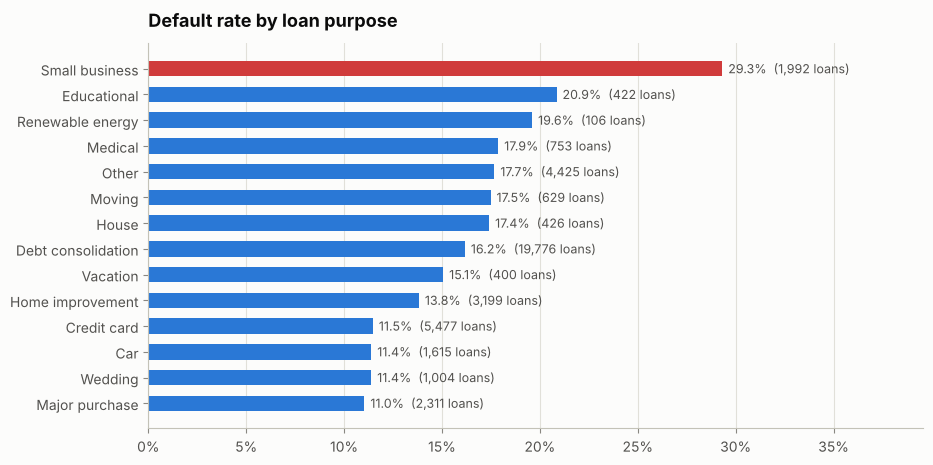

,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
purpose,,,,,,,
Debt consolidation,19776,"242,387,800.00",12.61,0.46,18692,0.16,0.09
Credit card,5477,"62,083,500.00",11.84,0.13,5273,0.11,0.11
Other,4425,"34,366,900.00",11.99,0.10,4214,0.18,0.06
Home improvement,3199,"35,447,325.00",11.60,0.08,3009,0.14,0.09
Major purchase,2311,"18,260,500.00",11.01,0.05,2219,0.11,0.09
Small business,1992,"26,167,400.00",13.16,0.05,1852,0.29,-0.02
Car,1615,"10,819,200.00",10.65,0.04,1492,0.11,0.10
Wedding,1004,"9,669,950.00",12.03,0.02,957,0.11,0.10
Medical,753,"6,017,475.00",11.68,0.02,716,0.18,0.05


In [25]:
purpose = risk_table("purpose").sort_values("default_rate")
fig, ax = plt.subplots(figsize=(10, 5))
colors = [CRITICAL if p == purpose["default_rate"].idxmax() else BLUE for p in purpose.index]
ax.barh(purpose.index, purpose["default_rate"], color=colors, height=0.6)
for y, (v, n) in enumerate(zip(purpose["default_rate"], purpose["loans"])):
    ax.text(v + 0.003, y, f"{v:.1%}  ({n:,} loans)", va="center", color=INK_2, fontsize=9)
pct_axis(ax, "x")
ax.set_xlim(0, purpose["default_rate"].max() * 1.35)
ax.set_title("Default rate by loan purpose")
ax.grid(axis="x")
save(fig, "05_default_rate_by_purpose")
purpose.sort_values("loans", ascending=False)

In [26]:
verification = risk_table("verification_status")
policy = risk_table("meets_credit_policy").rename(index={True: "Meets current policy", False: "Does not meet policy"})
display(verification)
policy

,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
verification_status,,,,,,,
Not Verified,18758,"154,974,325.00",11.45,0.44,18267,0.14,0.08
Source Verified,10306,"101,467,950.00",12.19,0.24,9664,0.16,0.08
Verified,13471,"203,853,875.00",13.14,0.32,12416,0.18,0.09


,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
meets_credit_policy,,,,,,,
Does not meet policy,2749,"24,292,425.00",14.15,0.06,2745,0.28,0.01
Meets current policy,39786,"436,003,725.00",12.03,0.94,37602,0.15,0.09


### 17.3 Borrower profile — income, DTI, employment, home ownership, credit behaviour

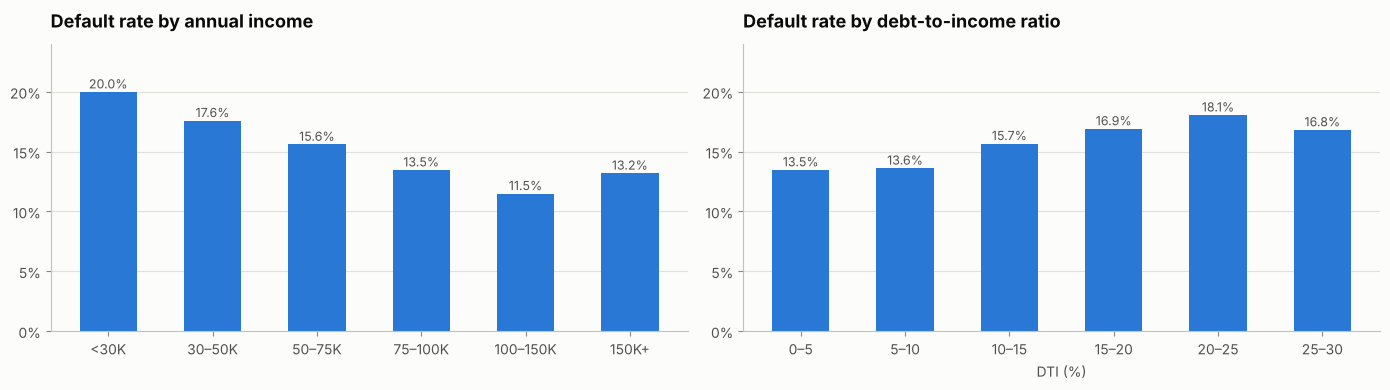

,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
income_band,,,,,,,
<30K,4209,"22,169,300.00",11.82,0.10,4078,0.20,0.03
30–50K,11643,"97,907,450.00",11.96,0.27,11078,0.18,0.07
50–75K,13002,"142,035,750.00",12.11,0.31,12314,0.16,0.08
75–100K,6986,"92,539,750.00",12.29,0.16,6594,0.13,0.09
100–150K,4700,"70,529,850.00",12.52,0.11,4430,0.11,0.12
150K+,1991,"35,088,850.00",13.17,0.05,1849,0.13,0.12


,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
dti_band,,,,,,,
0–5,5524,"51,815,875.00",11.27,0.13,5328,0.13,0.07
5–10,8526,"90,714,900.00",11.77,0.20,8144,0.14,0.09
10–15,10498,"116,956,725.00",12.18,0.25,9961,0.16,0.09
15–20,9768,"110,228,775.00",12.58,0.23,9227,0.17,0.09
20–25,7386,"81,004,650.00",12.86,0.17,6944,0.18,0.08
25–30,833,"9,575,225.00",10.88,0.02,743,0.17,0.07


In [27]:
income = risk_table("income_band")
dti_t = risk_table("dti_band")
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, t, title in [(axes[0], income, "Default rate by annual income"), (axes[1], dti_t, "Default rate by debt-to-income ratio")]:
    ax.bar(t.index.astype(str), t["default_rate"], color=BLUE, width=0.55)
    for x, v in zip(t.index.astype(str), t["default_rate"]):
        ax.text(x, v + 0.003, f"{v:.1%}", ha="center", color=INK_2, fontsize=9)
    pct_axis(ax)
    ax.set_ylim(0, max(income["default_rate"].max(), dti_t["default_rate"].max()) * 1.2)
    ax.set_title(title)
    ax.grid(axis="y")
axes[1].set_xlabel("DTI (%)")
fig.tight_layout()
save(fig, "06_default_by_income_and_dti")
display(income)
dti_t

In [28]:
home = risk_table("home_ownership")
emp = risk_table("emp_length")
inq = risk_table(pd.cut(df["inq_last_6mths"], [-1, 0, 1, 2, 3, 100], labels=["0", "1", "2", "3", "4+"]).rename("inquiries_6m"))
util = risk_table("revol_util_band")
display(home)
display(util)
inq

,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
home_ownership,,,,,,,
MORTGAGE,18959,"231,521,600.00",11.94,0.45,17772,0.15,0.09
OTHER,144,"1,321,325.00",12.57,0.00,144,0.21,0.04
OWN,3251,"32,449,775.00",11.92,0.08,3077,0.16,0.07
RENT,20181,"195,003,450.00",12.41,0.47,19354,0.16,0.08


,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
revol_util_band,,,,,,,
0–25%,10293,"101,947,075.00",10.01,0.24,9873,0.11,0.07
25–50%,11071,"118,892,925.00",11.39,0.26,10522,0.14,0.09
50–75%,11420,"131,728,600.00",12.81,0.27,10748,0.17,0.09
75–100%,9632,"107,147,900.00",14.58,0.23,9085,0.21,0.10
100%+,29,"160,375.00",13.18,0.00,29,0.38,-0.15


,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
inquiries_6m,,,,,,,
0,19657,"215,215,900.00",11.44,0.46,18530,0.12,0.10
1,11247,"121,605,675.00",12.50,0.26,10662,0.16,0.08
2,5987,"65,146,700.00",12.87,0.14,5676,0.17,0.08
3,3182,"33,641,175.00",13.01,0.07,3054,0.21,0.05
4+,2433,"24,575,625.00",13.66,0.06,2396,0.27,0.01


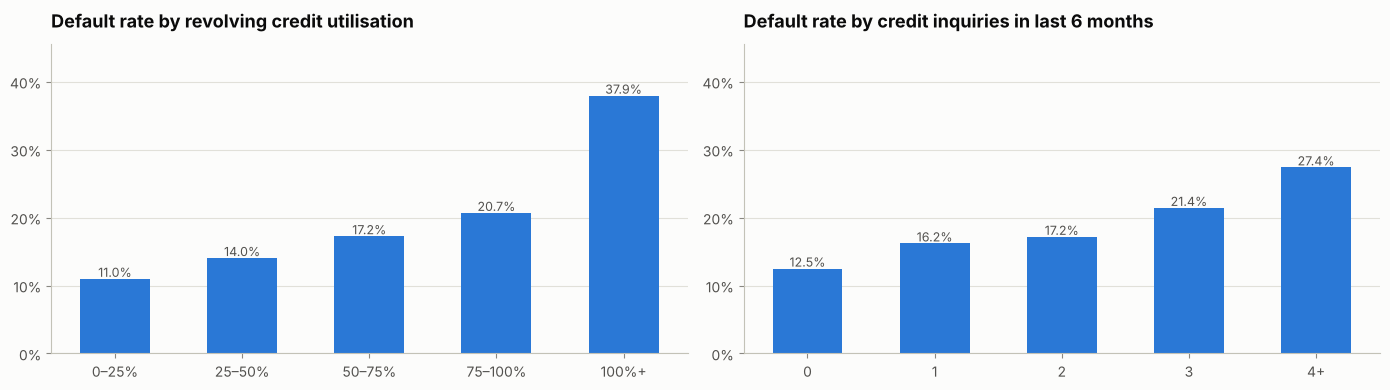

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, t, title in [(axes[0], util, "Default rate by revolving credit utilisation"),
                     (axes[1], inq, "Default rate by credit inquiries in last 6 months")]:
    ax.bar(t.index.astype(str), t["default_rate"], color=BLUE, width=0.55)
    for x, v in zip(t.index.astype(str), t["default_rate"]):
        ax.text(x, v + 0.003, f"{v:.1%}", ha="center", color=INK_2, fontsize=9)
    pct_axis(ax)
    ax.set_ylim(0, max(util["default_rate"].max(), inq["default_rate"].max()) * 1.2)
    ax.set_title(title)
    ax.grid(axis="y")
fig.tight_layout()
save(fig, "07_default_by_utilisation_and_inquiries")

### 17.4 High-value customers

In [30]:
hv = risk_table("is_high_income").rename(index={True: f"Top 10% income (≥ ${income_p90:,.0f})", False: "Other borrowers"})
big = risk_table(df["loan_amnt"] >= 25_000).rename(index={True: "Large loans ($25K+)", False: "Loans under $25K"})
display(hv)
big

,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
is_high_income,,,,,,,
Other borrowers,38281,"390,315,600.00",12.09,0.90,36358,0.16,0.08
"Top 10% income (≥ $116,736)",4254,"69,980,550.00",12.85,0.10,3989,0.13,0.12


,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return
loan_amnt,,,,,,,
Loans under $25K,39411,"375,930,875.00",11.94,0.93,37632,0.15,0.08
Large loans ($25K+),3124,"84,365,275.00",15.03,0.07,2715,0.22,0.09


### 17.5 Regions and states

In [31]:
region = risk_table("region").sort_values("funded", ascending=False)
region["funded_share"] = region["funded"] / region["funded"].sum()
state = risk_table("addr_state")
state["funded_share"] = state["funded"] / state["funded"].sum()
big_states = state[state["resolved_loans"] >= 500].sort_values("default_rate", ascending=False)   # enough finished loans
missing_states = sorted(set(dim_state["state_code"]) - set(df["addr_state"]))
print("States with no loans in the file:", missing_states)
display(region)
big_states.head(8)

States with no loans in the file: ['ND']


,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return,funded_share
region,,,,,,,,
South,13940,"151,007,475.00",12.15,0.33,13221,0.16,0.09,0.33
West,12044,"130,987,725.00",12.23,0.28,11492,0.17,0.07,0.28
Northeast,10414,"113,156,475.00",12.13,0.24,9840,0.14,0.10,0.25
Midwest,6137,"65,144,475.00",12.14,0.14,5794,0.15,0.09,0.14


,loans,funded,avg_rate,share_of_loans,resolved_loans,default_rate,net_return,funded_share
addr_state,,,,,,,,
FL,3104,"31,932,925.00",12.09,0.07,2936,0.20,0.05,0.07
MO,765,"7,779,275.00",11.96,0.02,731,0.19,0.08,0.02
GA,1503,"16,382,825.00",12.05,0.04,1432,0.17,0.08,0.04
MD,1125,"12,497,375.00",12.59,0.03,1078,0.17,0.09,0.03
CA,7429,"81,771,175.00",12.22,0.17,7117,0.17,0.07,0.18
WA,888,"9,518,350.00",12.32,0.02,839,0.17,0.06,0.02
NC,830,"9,087,550.00",12.11,0.02,756,0.16,0.07,0.02
NJ,1988,"22,435,325.00",12.38,0.05,1872,0.16,0.09,0.05


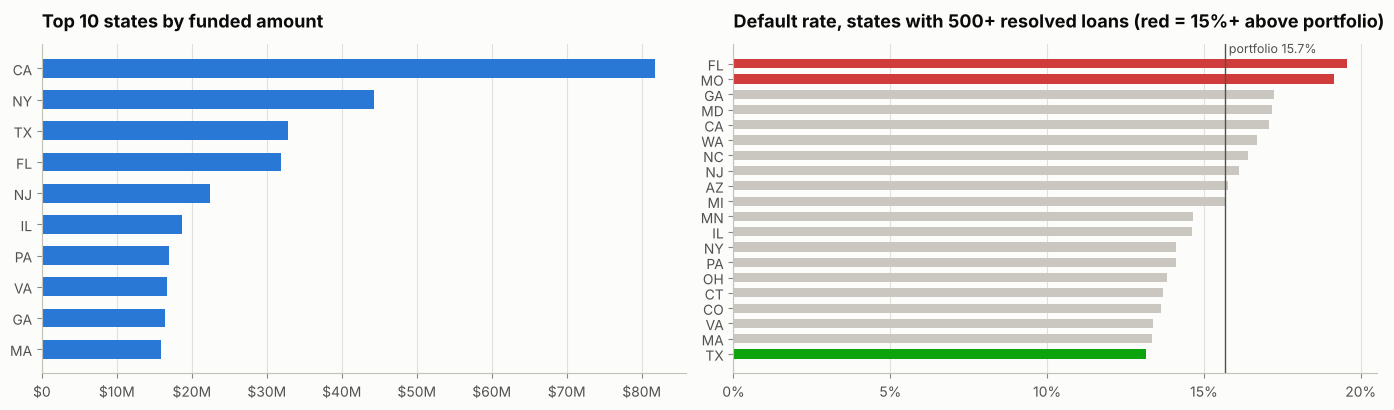

In [32]:
top_states = state.sort_values("funded", ascending=False).head(10)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
ax = axes[0]
ax.barh(top_states.index[::-1], top_states["funded"][::-1], color=BLUE, height=0.6)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(usd))
ax.set_title("Top 10 states by funded amount")
ax.grid(axis="x")
ax = axes[1]
bs = big_states.sort_values("default_rate")
overall = kpi["default_rate"]
colors = [CRITICAL if v > overall * 1.15 else (GOOD if v < overall * 0.85 else LIGHT_GRAY) for v in bs["default_rate"]]
ax.barh(bs.index, bs["default_rate"], color=colors, height=0.6)
ax.axvline(overall, color=INK_2, linewidth=1)
ax.text(overall, len(bs) - 0.3, f" portfolio {overall:.1%}", color=INK_2, fontsize=9)
pct_axis(ax, "x")
ax.xaxis.set_major_locator(mticker.MultipleLocator(0.05))
ax.set_title("Default rate, states with 500+ resolved loans (red = 15%+ above portfolio)")
ax.grid(axis="x")
fig.tight_layout()
save(fig, "08_states_volume_and_default")

## 18. Correlation analysis — which borrower features move with default?

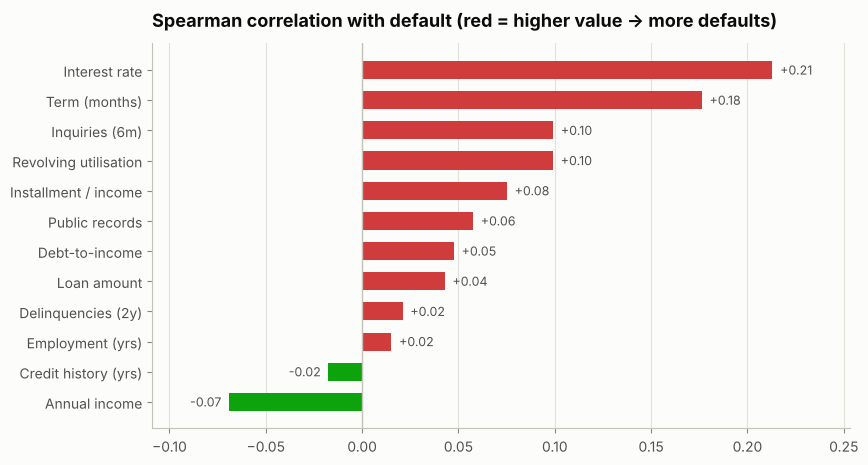

,spearman_corr_with_default
Annual income,-0.07
Credit history (yrs),-0.02
Employment (yrs),0.01
Delinquencies (2y),0.02
Loan amount,0.04
Debt-to-income,0.05
Public records,0.06
Installment / income,0.07
Revolving utilisation,0.10
Inquiries (6m),0.10


In [33]:
num_cols = {"int_rate": "Interest rate", "term_months": "Term (months)", "annual_inc": "Annual income",
            "dti": "Debt-to-income", "revol_util": "Revolving utilisation", "inq_last_6mths": "Inquiries (6m)",
            "credit_history_years": "Credit history (yrs)", "emp_length_years": "Employment (yrs)",
            "loan_amnt": "Loan amount", "installment_to_income": "Installment / income", "delinq_2yrs": "Delinquencies (2y)",
            "pub_rec": "Public records"}
corr_with_bad = (res[list(num_cols) + ["is_bad"]].astype(float).corr(method="spearman")["is_bad"]
                 .drop("is_bad").rename(index=num_cols).sort_values())
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(corr_with_bad.index, corr_with_bad.values,
        color=[CRITICAL if v > 0 else GOOD for v in corr_with_bad.values], height=0.6)
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_xlim(corr_with_bad.min() - 0.04, corr_with_bad.max() + 0.04)
for y, v in enumerate(corr_with_bad.values):
    ax.text(v + (0.004 if v >= 0 else -0.004), y, f"{v:+.2f}", va="center", ha="left" if v >= 0 else "right", color=INK_2, fontsize=9)
ax.set_title("Spearman correlation with default (red = higher value → more defaults)")
ax.grid(axis="x")
save(fig, "09_correlation_with_default")
corr_with_bad.round(3).to_frame("spearman_corr_with_default")

Correlation shows association, not cause. Interest rate correlates most because LendingClub *sets* the rate from the
borrower's risk — it summarises the other risk factors.

### Save the KPI summary (source of every number in the README and reports)

In [34]:
def py(v):
    if isinstance(v, (np.integer,)):
        return int(v)
    if isinstance(v, (np.floating, float)):
        return round(float(v), 6)   # 6 decimals: avoids double rounding when reports show 1-decimal percentages
    if isinstance(v, (np.bool_,)):
        return bool(v)
    return v


def as_dict(series):
    return {str(k): py(v) for k, v in series.items()}


summary = {k: py(v) for k, v in kpi.items()}
summary.update({
    "rows_read": int(raw.shape[0]), "non_loan_rows": int(len(non_loan_rows)), "raw_columns": int(raw.shape[1]),
    "empty_columns": len(empty_columns), "dropped_columns": len(drop_cols), "clean_columns": int(loans.shape[1]),
    "footer_total": footer_total, "installment_formula_match": dq["installment matches amortisation formula (±$1)"],
    "partly_funded_loans": dq["funded_amnt < loan_amnt (partly funded)"],
    "first_issue": str(df["issue_d"].min().date()), "last_issue": str(df["issue_d"].max().date()),
    "income_p90": py(income_p90), "income_fence": py(fence),
    "vintage_loans": as_dict(vintage["loans"]), "vintage_funded": as_dict(vintage["funded"]),
    "vintage_default_rate": as_dict(vintage["default_rate"]), "vintage_avg_rate": as_dict(vintage["avg_rate"]),
    "funded_growth_2010_2011_pct": py(vintage.loc[2011, "funded_growth_pct"]),
    "grade_default_rate": as_dict(grade["default_rate"]), "grade_avg_rate": as_dict(grade["avg_rate"]),
    "grade_net_return": as_dict(grade["net_return"]), "grade_share": as_dict(grade["share_of_loans"]),
    "grade36_net_return": as_dict(grade_36["net_return"]), "grade36_default_rate": as_dict(grade_36["default_rate"]),
    "emp_unknown_default_rate": py(emp.loc["Unknown", "default_rate"]),
    "emp_known_default_rate": py(df[df["is_resolved"] & (df["emp_length"] != "Unknown")]["is_bad"].mean()),
    "verified_share_2011": py((df.loc[df["issue_year"] == 2011, "verification_status"] != "Not Verified").mean()),
    "active_share_2011": py(active_2011),
    "vintage_resolved_share": as_dict(vintage["resolved_share"]),
    "term_default_rate": as_dict(term["default_rate"]), "term_net_return": as_dict(term["net_return"]),
    "term_grade_default": {f"{g}_{t}": py(v) for (g, t), v in term_grade.stack().items()},
    "purpose_default_rate": as_dict(purpose["default_rate"]), "purpose_loans": as_dict(purpose["loans"]),
    "verification_default_rate": as_dict(verification["default_rate"]),
    "policy_default_rate": as_dict(policy["default_rate"]),
    "income_default_rate": as_dict(income["default_rate"]), "dti_default_rate": as_dict(dti_t["default_rate"]),
    "home_default_rate": as_dict(home["default_rate"]), "home_share": as_dict(home["share_of_loans"]),
    "util_default_rate": as_dict(util["default_rate"]), "inq_default_rate": as_dict(inq["default_rate"]),
    "emp_default_rate": as_dict(emp["default_rate"]),
    "high_income_default_rate": py(hv.loc[hv.index.str.startswith("Top"), "default_rate"].iloc[0]),
    "high_income_table": {str(k): as_dict(v) for k, v in hv[["loans", "default_rate", "net_return", "avg_rate"]].iterrows()},
    "large_loan_table": {str(k): as_dict(v) for k, v in big[["loans", "default_rate", "net_return", "avg_rate"]].iterrows()},
    "region_funded_share": as_dict(region["funded_share"]), "region_default_rate": as_dict(region["default_rate"]),
    "worst_state": big_states.index[0], "worst_state_default_rate": py(big_states["default_rate"].iloc[0]),
    "best_state": big_states.index[-1], "best_state_default_rate": py(big_states["default_rate"].iloc[-1]),
    "top_state": top_states.index[0], "top_state_funded_share": py(top_states["funded_share"].iloc[0]),
    "missing_states": missing_states,
    "corr_with_default": as_dict(corr_with_bad),
})
(REPORTS / "kpi_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(f"Saved {len(summary)} values to reports/kpi_summary.json")

Saved 84 values to reports/kpi_summary.json


## 19. Visualisations

Saved in `reports/figures/`: `01_distributions`, `02_grade_and_purpose_mix`, `03_growth_and_vintage_default`,
`04_grade_rate_default_return`, `05_default_rate_by_purpose`, `06_default_by_income_and_dti`,
`07_default_by_utilisation_and_inquiries`, `08_states_volume_and_default`, `09_correlation_with_default`.

## 20. Key findings

1. **Portfolio.** 42,535 loans worth $460.3M were funded between June 2007 and December 2011; funded volume grew
   +104% in 2011 alone. Average loan $11,090, average rate 12.17%, 25.9% of loans are 60-month.
2. **Risk.** Of 40,347 finished loans, **15.7% were charged off**, losing $44.3M of principal after
   recoveries (loss-given-default 61.4%). Interest still covered the losses: the resolved portfolio returned **8.5%** net.
3. **Grades price risk — up to a point.** Default rises steadily from **6.0% (grade A) to 36.2% (grade G)** while rates rise
   from 7.3% to 20.5%. Comparing like with like (36-month loans), net return climbs from 7.1% (A) to 9.8% (D) but
   **collapses to 0.1% for F and 2.7% for G** — the highest rates do not cover the losses of the riskiest grades.
4. **60-month loans are much riskier:** 27.8% default vs 12.3% for 36-month loans.
5. **Small-business loans are the riskiest purpose (29.3%)**, almost double debt consolidation (16.2%), while car, major-purchase
   and credit-card refinancing loans default least.
6. **Income and DTI matter:** borrowers earning <$30K default at 20.0% vs 11.5% for $100–150K; DTI
   20–25 defaults at 18.1% vs 13.5% for DTI 0–5.
7. **Credit behaviour signals risk:** 100%+ revolving utilisation defaults at 37.9% vs 11.0% for 0–25%; 4+ inquiries
   in 6 months at 27.4% vs 12.5% with none.
8. **Policy exceptions:** 2,749 loans (6.5%) would not meet the current credit policy; they defaulted at
   27.7% vs 14.8%.
9. **Verified income did not mean lower risk:** verified borrowers defaulted at 17.6% vs 14.5% for
   not-verified — verification was used more for riskier and larger applications, so it is a flag of perceived risk, not a guarantee.
   **Missing employment length is a red flag:** 23.2% default vs 15.5% when it is provided.
10. **Regions:** CA is the biggest market (17.8% of funded volume); among states with 500+ resolved loans,
    FL has the highest default rate (19.6%) and TX the lowest (13.2%).
11. **Funding:** 97.6% of the requested amount was funded; 1,997 loans were only partly funded.

## 21. Business recommendations

| # | Recommendation | Based on |
|---|---|---|
| 1 | **Tighten or re-price small-business loans** (extra documentation, lower limits, or a higher rate) — they default at 29.3%. | Finding 5 |
| 2 | **Limit 60-month terms for lower grades** (E–G), where long terms combine with high default; offer 36 months instead. | Findings 3–4 |
| 3 | **Add hard limits on very high DTI and utilisation** (e.g. DTI > 25, utilisation > 100%) or require a higher grade for them. | Findings 6–7 |
| 4 | **Re-price or cap grades F–G**: on 36-month loans they returned only 0.1% and 2.7%, vs 9.8% for grade D. | Finding 3 |
| 5 | **Keep the tightened credit policy** — loans that would fail it defaulted much more often; treat missing employment data as a reason for manual review. | Findings 8–9 |
| 6 | **Grow the best risk-adjusted segments** (grades B–C, 36-month, credit-card refinancing) in the largest states. | Findings 3–5, 10 |
| 7 | **Collect rejected-application data** to measure approval rates and test whether policy changes reduce good-customer rejections. | Limitation |